# Airbnb Listings EDA — Chicago vs New Orleans
Step-by-step cleaning, transformation, and exploratory analysis. Each step is its own cell with comments explaining the *why*, not just the *what*.

##1. Imports

In [ ]:
# Core data libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Make plots render inline and set a consistent style
%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

##2.Load Raw Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Load each city's listings file separately first.
# Loading separately (before merging) lets us catch city-specific issues,
# e.g. a column that's empty in one file but not the other.
chi = pd.read_csv(r"/content/drive/MyDrive/AlmaBetter Capstone Project/Module4_Transforming_EDAs_to_Dashboards/Chicago.csv")            # Chicago
nola = pd.read_csv(r"/content/drive/MyDrive/AlmaBetter Capstone Project/Module4_Transforming_EDAs_to_Dashboards/New_Orleans.csv")       # New Orleans

# Tag each dataframe with its city BEFORE merging.
# Tagging after merging is a common source of mislabeled rows.
chi["city"] = "Chicago"
nola["city"] = "New Orleans"

# Merge into a single working dataframe
df = pd.concat([chi, nola], ignore_index=True)

df.shape

(15958, 20)

##3.Initial Inspection

In [ ]:
# Check column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15958 entries, 0 to 15957
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              15958 non-null  int64  
 1   name                            15958 non-null  object 
 2   host_id                         15849 non-null  float64
 3   host_profile_id                 15729 non-null  float64
 4   host_name                       15730 non-null  object 
 5   neighbourhood_group             0 non-null      float64
 6   neighbourhood                   15958 non-null  object 
 7   latitude                        15958 non-null  float64
 8   longitude                       15958 non-null  float64
 9   room_type                       15958 non-null  object 
 10  price                           14126 non-null  float64
 11  minimum_nights                  15949 non-null  float64
 12  number_of_reviews               

In [ ]:
# Check null counts per column - this drives every decision below
df.isna().sum().sort_values(ascending=False)

,0
neighbourhood_group,15958
license,4296
reviews_per_month,2796
last_review,2796
price,1832
host_profile_id,229
host_name,228
host_id,109
calculated_host_listings_count,109
minimum_nights,9


In [ ]:
# Quick statistical summary of numeric coulumns
# (useful for spotting obvious outliers, e.g. a max price in the thousands)
df.describe()

,id,host_id,host_profile_id,neighbourhood_group,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm
count,1.595800e+04,1.584900e+04,1.572900e+04,0.0,15958.000000,15958.000000,14126.000000,15949.000000,15958.000000,13162.000000,15849.000000,15958.000000,15958.000000
mean,7.926830e+17,3.812319e+15,1.473058e+18,NaN,36.466114,-88.757432,293.676695,13.740423,65.489284,1.761772,26.719604,223.628400,13.535844
std,6.243890e+17,7.990486e+16,3.047435e+16,NaN,5.941694,1.201160,376.267803,24.235568,105.760112,2.001376,73.317879,117.013827,23.795618
min,2.384000e+03,2.613000e+03,1.462506e+18,NaN,29.897042,-90.135521,3.000000,1.000000,0.000000,0.010000,1.000000,0.000000,0.000000
25%,4.517905e+07,4.773946e+07,1.462954e+18,NaN,29.959916,-90.071217,128.250000,2.000000,2.000000,0.450000,1.000000,134.000000,0.000000
50%,9.197043e+17,1.679214e+08,1.467362e+18,NaN,41.784480,-87.722660,207.000000,2.000000,23.000000,1.390000,4.000000,261.000000,5.000000
75%,1.349523e+18,4.509308e+08,1.469997e+18,NaN,41.897053,-87.652206,339.750000,30.000000,87.000000,2.570000,18.000000,325.000000,22.000000
max,1.714532e+18,1.710597e+18,1.710597e+18,NaN,42.021360,-87.528420,9501.000000,1125.000000,2179.000000,77.090000,436.000000,365.000000,1231.000000


In [ ]:
#Preview a few rows to sanity-check the actual values, not just the schema
df.head()

,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license,city
0,2384,Hyde Park: 5 minute walk to Obama Presidential...,2613.0,1.462506e+18,Rebecca,NaN,Hyde Park,41.78790,-87.58780,Private room,171.0,2.0,268,2026-06-08,1.92,1.0,310,14,R17000015609,Chicago
1,7126,Tiny Studio Apartment 94 Walk Score,17928.0,1.462507e+18,Sarah,NaN,West Town,41.90166,-87.68021,Entire home/apt,112.0,2.0,626,2026-05-25,3.03,1.0,247,43,R26000138446,Chicago
2,10945,The Biddle House (#1),33004.0,1.462507e+18,Elizabeth,NaN,Lincoln Park,41.91196,-87.63981,Entire home/apt,280.0,4.0,152,2026-06-06,1.03,6.0,283,29,2209984,Chicago
3,12140,Lincoln Park Guest House,46734.0,1.462508e+18,Shar And Robert,NaN,Lincoln Park,41.92357,-87.64947,Private room,422.0,2.0,21,2026-06-21,0.16,1.0,136,3,2398451,Chicago
4,71930,"Rest, Relax and Explore",334241.0,1.462511e+18,Michael And Veronica,NaN,West Town,41.89615,-87.67934,Private room,109.0,3.0,158,2026-06-02,0.86,1.0,326,22,R23000108832,Chicago


## 4. Data Cleaning

In [ ]:
# neighbourhood_group is completely empty in both source file(comfirmed above).
# A 100%-null column adds nothing, so drop it rather than keep it as dead weight.
df = df.drop(columns = ["neighbourhood_group"])

In [ ]:
# Remove exact duplicate listings by id
before = len(df)
df = df.drop_duplicates(subset=["id"])
print(f"Duplicates removed: {before-len(df)}")

Duplicates removed: 0


In [ ]:
# Ensure price is numeric (strip $ and commas if it was loaded as a string)
if df["price"].dtype == object:
    df["price"] = (
        df["price"].astype(str)
        .str.replace(r"[$,]", "", regex=True)
        .astype(float)
    )

# Drop rows with no price at all.
# Price is the central metric for almost every chart, and there's no
# defensible way to impute a missing price without inventing data.
before = len(df)
df = df.dropna(subset=["price"])
print(f"Rows dropped for missing price: {before - len(df)}")

Rows dropped for missing price: 1832


In [ ]:
# minimum_nights: fill any rare nulls with the per-city median
# (median, not mean, because minimum_nights is often skewed by
# a small number of hosts requiring very long stays)
df["minimum_nights"] = df.groupby("city")["minimum_nights"].transform(
    lambda x: x.fillna(x.median())
)

In [ ]:
# reviews_per_month nulls need care: a null here usually means the listing
# has zero reviews yet, which is a valid value of 0 — NOT missing data.
df.loc[df["number_of_reviews"] == 0, "reviews_per_month"] = (
    df.loc[df["number_of_reviews"] == 0, "reviews_per_month"].fillna(0)
)

# Any remaining rare nulls are true data gaps — fill conservatively with 0
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

In [ ]:
# Standardize neighbourhood text: trim whitespace and normalize casing.
# This is the pandas equivalent of Tableau/Power BI Prep's "Group and Replace" —
# doing it once here avoids fixing the same inconsistency in every chart later.
df["neighbourhood"] = df["neighbourhood"].astype(str).str.strip().str.title()

In [ ]:
# Parse last_review into a real datetime so we can do date arithmetic later
df["last_review"] = pd.to_datetime(df["last_review"], errors="coerce")

In [ ]:
# host_name: fill missing names with a placeholder rather than dropping rows
# (a missing name doesn't affect price/location analysis, so the row is still useful)
df["host_name"] = df["host_name"].fillna("Unknown")

In [ ]:
# license: many blanks here are legitimate (unlicensed or exempt listings),
# not dirty data — so keep the column and add a flag instead of imputing anything
df["has_license"] = df["license"].notna()

In [ ]:
# A boolean is handy for filtering/aggregating, but reads awkwardly as a chart
# axis label in Tableau/Power BI — add a clean categorical label for display.
# The raw license ID column is left untouched; this is purely a display-friendly
# derived column, not a cleaning fix.
df["license_status"] = df["has_license"].map({True: "Licensed", False: "Unlicensed"})

print(df.groupby("city")["license_status"].value_counts())

city         license_status
Chicago      Licensed          5409
             Unlicensed        2236
New Orleans  Licensed          5360
             Unlicensed        1121
Name: count, dtype: int64


## 5. Outlier Handling

In [ ]:
# Cap price at the 99th percentile PER CITY (not globally — Chicago and
# New Orleans have different price ceilings, so a global cap would
# under-cap one city and over-cap the other).
cap = df.groupby("city")["price"].transform(lambda x: x.quantile(0.99))

# Flag outliers rather than deleting them, so downstream users can
# choose to include or exclude them
df["price_outlier_flag"] = df["price"] > cap
df["price_capped"] = np.where(df["price_outlier_flag"], cap, df["price"])

print(f"Price outliers capped: {df['price_outlier_flag'].sum()}")

Price outliers capped: 140


## 6. Feature Engineering (Derived Columns)

In [ ]:
# Price band — makes price usable as a categorical filter in visuals
df["price_band"] = pd.cut(
    df["price_capped"],
    bins=[0, 75, 150, 300, np.inf],
    labels=["Budget (<$75)", "Mid ($75-150)", "High ($150-300)", "Luxury ($300+)"]
    )

In [ ]:
# Availability band — groups raw days-available into readable buckets
df["availability_band"] = pd.cut(
    df["availability_365"],
    bins=[-1, 0, 90, 180, 365],
    labels=["Never available", "Low (1-90 days)", "Moderate (91-180)", "High (181-365)"]
)

In [ ]:
# Host type — based on how many listings each host_id operates.
# This is the column that later reveals the strongest insight in the project:
# pricing differences between casual and professional hosts.
host_counts = df.groupby("host_id")["id"].transform("count")

df["host_type"] = np.select(
    [host_counts == 1, host_counts.between(2, 5), host_counts > 5],
    ["Single-listing host", "Small multi-host (2-5)", "Professional host (6+)"],
    default="Unknown"
)

In [ ]:
# is_active — flags listings reviewed within the last 12 months
# relative to the most recent review date in the whole dataset
most_recent = df["last_review"].max()
df["is_active"] = ((most_recent - df["last_review"]).dt.days <= 365).fillna(False)

In [ ]:
# log_price — price is heavily right-skewed, so a log transform is used
# for any scatter plot or model that assumes a roughly linear/normal relationship
df["log_price"] = np.log1p(df["price_capped"])

In [ ]:
# revenue_proxy — an ILLUSTRATIVE estimate only (occupancy is assumed, not observed).
# Always state this assumption out loud when presenting it.
assumed_occupancy = 0.5
df["revenue_proxy"] = df["price_capped"] * (365 - df["availability_365"]) * assumed_occupancy

In [ ]:
# Final sanity check on the cleaned, transformed dataset
print(f"Final row count: {len(df)}")
print(df['city'].value_counts())
df.head(3)

Final row count: 14126
city
Chicago        7645
New Orleans    6481
Name: count, dtype: int64


,id,name,host_id,host_profile_id,host_name,neighbourhood,latitude,longitude,room_type,price,...,has_license,license_status,price_outlier_flag,price_capped,price_band,availability_band,host_type,is_active,log_price,revenue_proxy
0,2384,Hyde Park: 5 minute walk to Obama Presidential...,2613.0,1.462506e+18,Rebecca,Hyde Park,41.78790,-87.58780,Private room,171.0,...,True,Licensed,False,171.0,High ($150-300),High (181-365),Single-listing host,True,5.147494,4702.5
1,7126,Tiny Studio Apartment 94 Walk Score,17928.0,1.462507e+18,Sarah,West Town,41.90166,-87.68021,Entire home/apt,112.0,...,True,Licensed,False,112.0,Mid ($75-150),High (181-365),Single-listing host,True,4.727388,6608.0
2,10945,The Biddle House (#1),33004.0,1.462507e+18,Elizabeth,Lincoln Park,41.91196,-87.63981,Entire home/apt,280.0,...,True,Licensed,False,280.0,High ($150-300),High (181-365),Professional host (6+),True,5.638355,11480.0


## 7. Univariate Analysis
Looking at one variable at a time to understand what's typical before comparing anything.

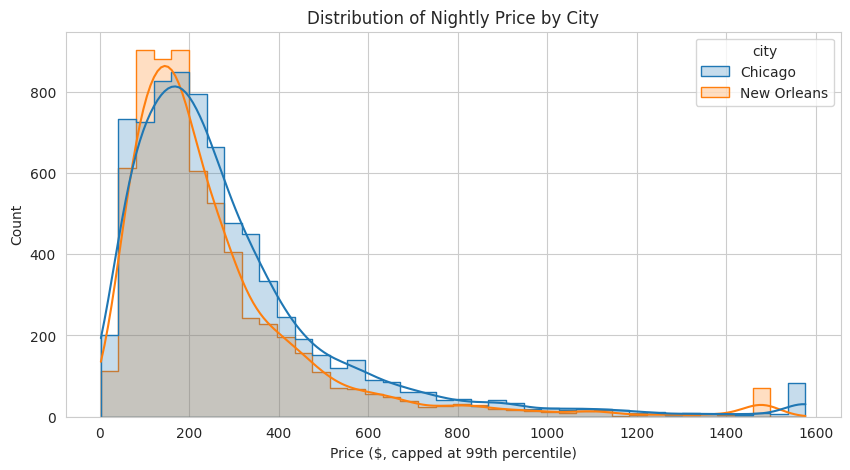

In [ ]:
# Distribution of nightly price (capped), split by city
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="price_capped", hue="city", bins=40, kde=True, element="step")
plt.title("Distribution of Nightly Price by City")
plt.xlabel("Price ($, capped at 99th percentile)")
plt.show()

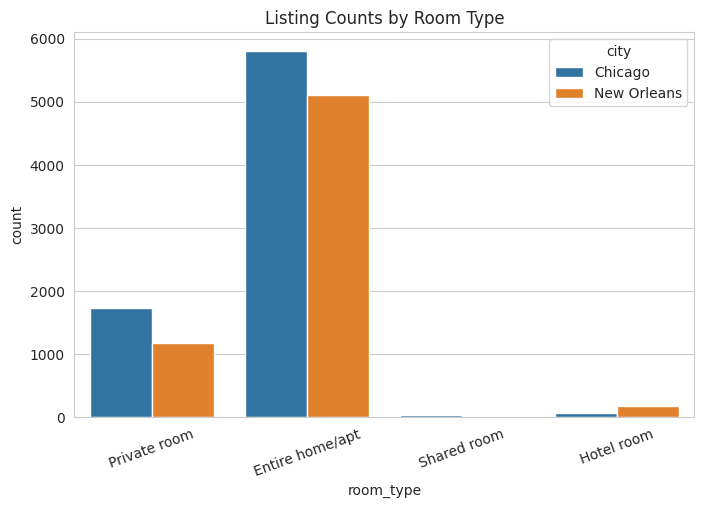

In [ ]:
# Room type counts by city
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="room_type", hue="city")
plt.title("Listing Counts by Room Type")
plt.xticks(rotation=20)
plt.show()

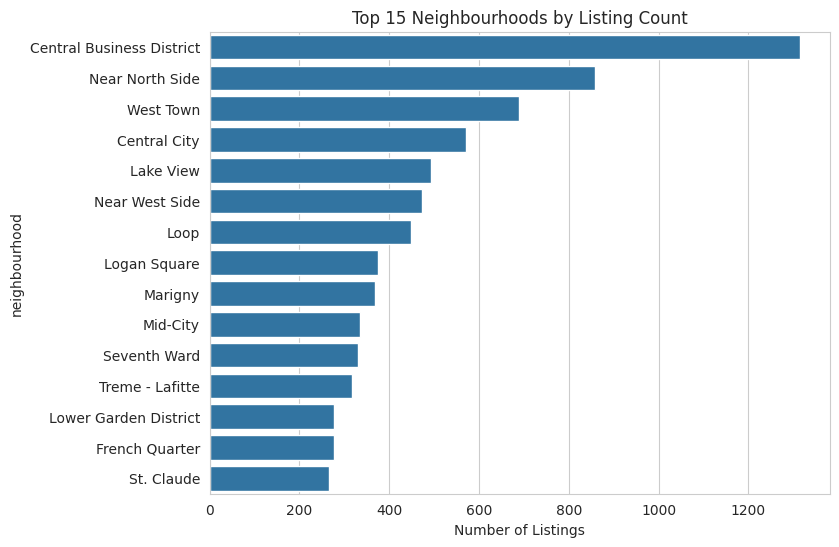

In [ ]:
# Top 15 neighbourhoods by listing count (both cities combined)
top_neighbourhoods = df["neighbourhood"].value_counts().head(15)
plt.figure(figsize=(8, 6))
sns.barplot(x=top_neighbourhoods.values, y=top_neighbourhoods.index, orient="h")
plt.title("Top 15 Neighbourhoods by Listing Count")
plt.xlabel("Number of Listings")
plt.show()

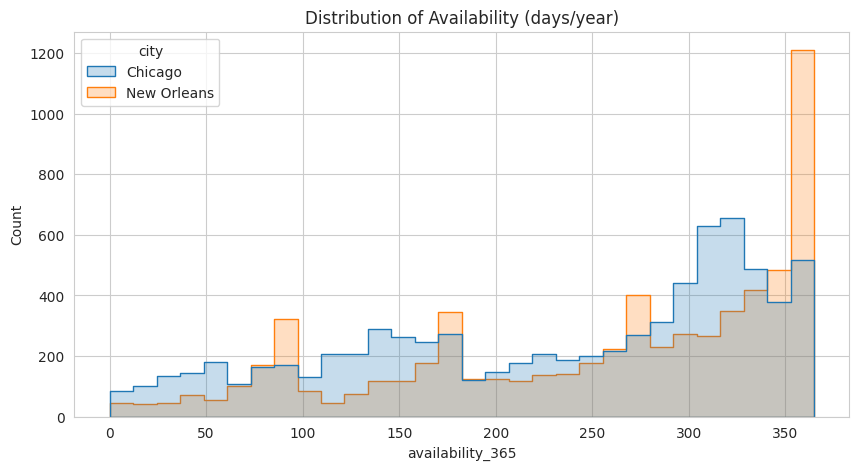

In [ ]:
# Availability distribution — how many days per year listings are bookable
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="availability_365", hue="city", bins=30, element="step")
plt.title("Distribution of Availability (days/year)")
plt.show()

## 8. Bivariate Analysis
Comparing two variables at a time to find relationships.

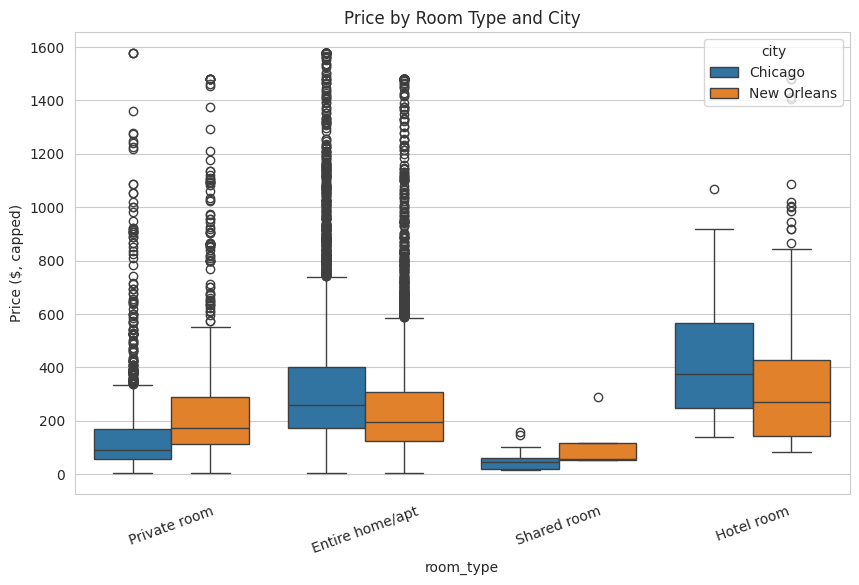

In [ ]:
# Price by room type, split by city
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="room_type", y="price_capped", hue="city")
plt.title("Price by Room Type and City")
plt.ylabel("Price ($, capped)")
plt.xticks(rotation=20)
plt.show()

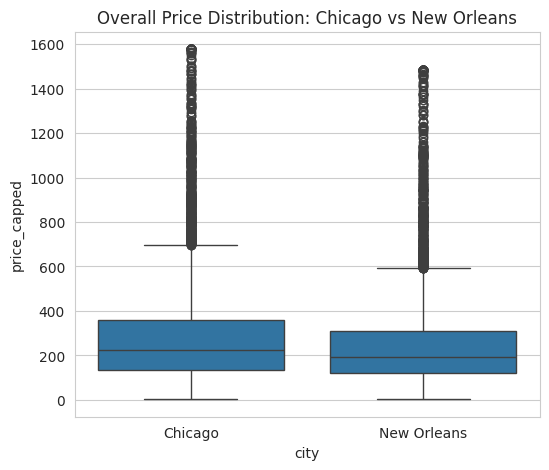

In [ ]:
# Overall price comparison between the two cities
plt.figure(figsize=(6, 5))
sns.boxplot(data=df, x="city", y="price_capped")
plt.title("Overall Price Distribution: Chicago vs New Orleans")
plt.show()

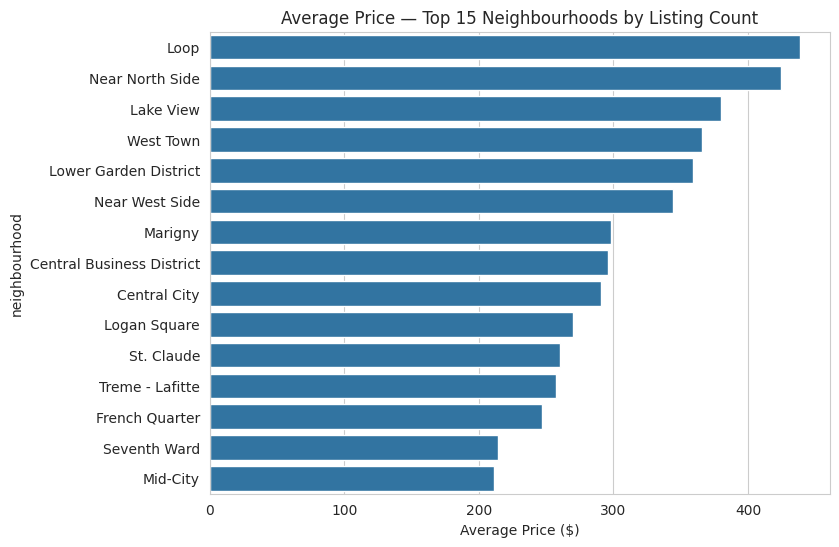

In [ ]:
# Average price for the top 15 neighbourhoods by listing count
top_names = df["neighbourhood"].value_counts().head(15).index
avg_price_by_neigh = (
    df[df["neighbourhood"].isin(top_names)]
    .groupby("neighbourhood")["price_capped"]
    .mean()
    .sort_values(ascending=False)
)
plt.figure(figsize=(8, 6))
sns.barplot(x=avg_price_by_neigh.values, y=avg_price_by_neigh.index, orient="h")
plt.title("Average Price — Top 15 Neighbourhoods by Listing Count")
plt.xlabel("Average Price ($)")
plt.show()

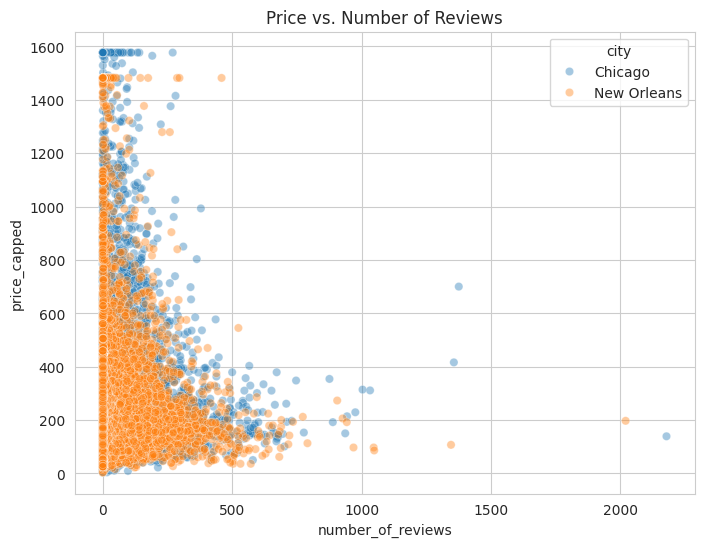

In [ ]:
# Price vs. number of reviews — does higher price correlate with more or fewer reviews?
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="number_of_reviews", y="price_capped", hue="city", alpha=0.4)
plt.title("Price vs. Number of Reviews")
plt.show()

## 9. Multivariate Analysis
Combining three or more variables together — this is where the strongest insight in the project appears.

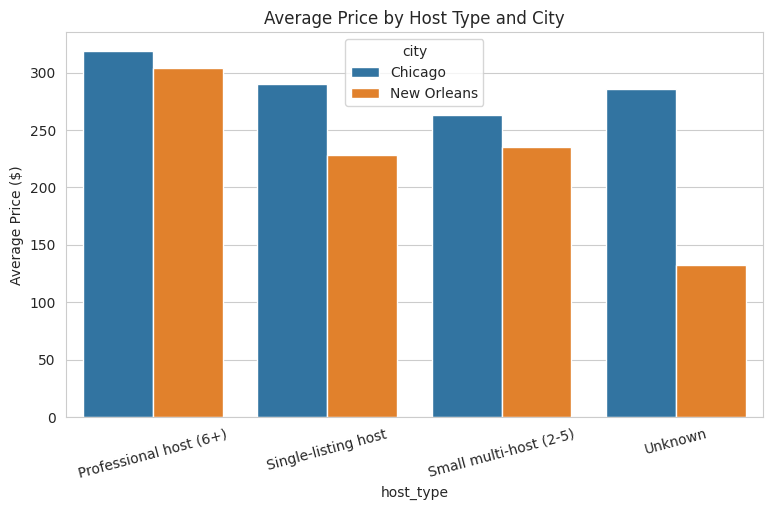

,city,host_type,price_capped
0,Chicago,Professional host (6+),319.070052
1,Chicago,Single-listing host,290.093725
2,Chicago,Small multi-host (2-5),263.422258
3,Chicago,Unknown,286.113636
4,New Orleans,Professional host (6+),304.143058
5,New Orleans,Single-listing host,228.649709
6,New Orleans,Small multi-host (2-5),235.091755
7,New Orleans,Unknown,132.639344


In [ ]:
# Average price by host type, split by city
# This is the key multivariate finding: the price gap between professional
# and single-listing hosts is very different in size between the two cities.
price_by_host_city = (
    df.groupby(["city", "host_type"])["price_capped"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))
sns.barplot(data=price_by_host_city, x="host_type", y="price_capped", hue="city")
plt.title("Average Price by Host Type and City")
plt.ylabel("Average Price ($)")
plt.xticks(rotation=15)
plt.show()

price_by_host_city

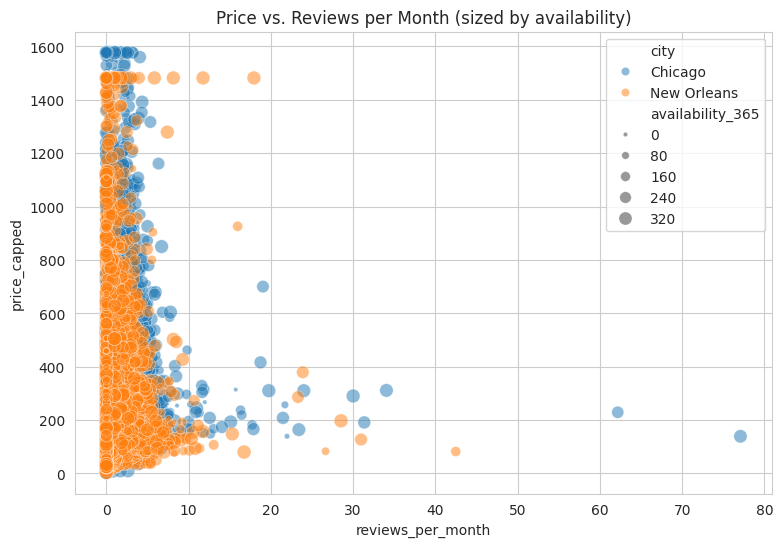

In [ ]:
# Price vs. reviews-per-month, colored by city, sized by availability —
# three variables in one view to see if the price/reviews relationship
# differs by how much inventory a listing makes available
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df, x="reviews_per_month", y="price_capped",
    hue="city", size="availability_365", alpha=0.5, sizes=(10, 100)
)
plt.title("Price vs. Reviews per Month (sized by availability)")
plt.show()

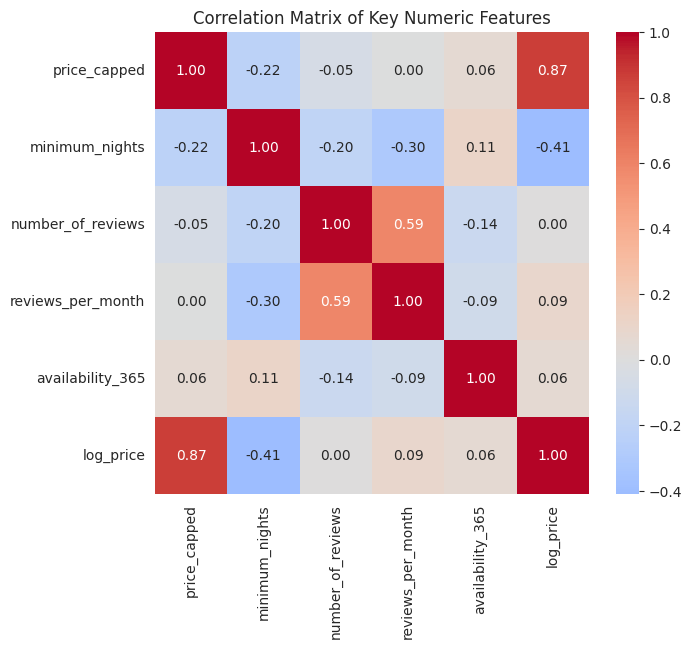

In [ ]:
# Correlation heatmap of key numeric features
numeric_cols = ["price_capped", "minimum_nights", "number_of_reviews",
                 "reviews_per_month", "availability_365", "log_price"]
corr = df[numeric_cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Key Numeric Features")
plt.show()

## 10. Export Cleaned Dataset

In [ ]:
# Export the cleaned, transformed dataset for use in Tableau or Power BI
df.to_csv("airbnb_chicago_neworleans_clean.csv", index=False)
print("Exported:", df.shape)

Exported: (14126, 29)


In [ ]:
# Triggers a browser download popup in Google Colab.
# If it's blocked, allow downloads for colab.research.google.com and re-run.
from google.colab import files
files.download('airbnb_chicago_neworleans_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>